# Identity & Access Security Analytics Pipeline
## Cloud Identity Governance, Behavioral Auth Anomaly Detection & CIEM
---
### Module Scope (Member 1):
1. **C1: Brute Force Detector**: Stateful sliding time window monitoring failed logins per IP/user.
2. **C2: Impossible Travel Detector**: Geolocation velocity calculation via Haversine spherical distance.
3. **C3: Privilege Escalation Detector**: IAM policy attachment and unauthorized permission expansion.
4. **C16: MFA Fatigue Detector**: Rapid repeated multi-factor authentication push prompts.
5. **CIEM Engine**: Inactive credential discovery and overprivileged role analysis.

### Step 1: Library Imports & Environment Setup

In [1]:
import os
import sys
import time
import math
from datetime import datetime, timezone, timedelta
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Environment initialized for Identity & Access Security Analytics.")

Environment initialized for Identity & Access Security Analytics.


### Step 2: C1 - Brute Force Authentication Detection Engine
Tracks failed login attempts across a sliding 300-second window. Triggers critical alert when failed logins exceed threshold (5).

In [2]:
class BruteForceDetector:
    def __init__(self, window_sec=300, threshold=5):
        self.window_sec = window_sec
        self.threshold = threshold
        self.failures = {}

    def process_event(self, event):
        if event.get('action') != 'ConsoleLogin':
            return None
        ip = event.get('src_ip', 'unknown')
        now = event.get('timestamp')
        if ip not in self.failures:
            self.failures[ip] = []
        
        # Evict timestamps older than sliding window
        self.failures[ip] = [t for t in self.failures[ip] if (now - t).total_seconds() <= self.window_sec]
        
        if event.get('status') == 'failure':
            self.failures[ip].append(now)
            if len(self.failures[ip]) >= self.threshold:
                return {
                    'alert': 'C1_BRUTE_FORCE_DETECTED',
                    'severity': 'HIGH',
                    'src_ip': ip,
                    'attempts': len(self.failures[ip]),
                    'user': event.get('user')
                }
        return None

# Simulate synthetic authentication stream
base_time = datetime(2026, 10, 29, 10, 0, 0, tzinfo=timezone.utc)
events = []
# Normal traffic
for i in range(10):
    events.append({'action': 'ConsoleLogin', 'src_ip': '192.168.1.50', 'status': 'success', 'user': 'dev_user', 'timestamp': base_time + timedelta(seconds=i*30)})
# Attack burst from 203.0.113.88
for i in range(7):
    events.append({'action': 'ConsoleLogin', 'src_ip': '203.0.113.88', 'status': 'failure', 'user': 'admin', 'timestamp': base_time + timedelta(seconds=120 + i*10)})

detector = BruteForceDetector()
alerts = []
for ev in events:
    res = detector.process_event(ev)
    if res:
        alerts.append(res)

print(f"Processed {len(events)} login events. Alerts generated: {len(alerts)}")
for a in alerts:
    print(f"  -> {a}")

Processed 17 login events. Alerts generated: 3
  -> {'alert': 'C1_BRUTE_FORCE_DETECTED', 'severity': 'HIGH', 'src_ip': '203.0.113.88', 'attempts': 5, 'user': 'admin'}
  -> {'alert': 'C1_BRUTE_FORCE_DETECTED', 'severity': 'HIGH', 'src_ip': '203.0.113.88', 'attempts': 6, 'user': 'admin'}
  -> {'alert': 'C1_BRUTE_FORCE_DETECTED', 'severity': 'HIGH', 'src_ip': '203.0.113.88', 'attempts': 7, 'user': 'admin'}


### Step 3: C2 - Impossible Travel Detection Engine (Haversine Formula)
Calculates the great-circle distance between successive logins from the same user identity.
$$\text{Velocity} = \frac{\text{HaversineDistance}(\text{loc}_1, \text{loc}_2)}{\Delta t}$$
If velocity exceeds physical aircraft transit ($> 800\text{ km/h}$), trigger high-severity alert.

In [3]:
def haversine_distance_km(lat1, lon1, lat2, lon2):
    R = 6371.0  # Earth radius in kilometers
    dlat = math.radians(lat2 - lat1)
    dlon = math.radians(lon2 - lon1)
    a = math.sin(dlat / 2)**2 + math.cos(math.radians(lat1)) * math.cos(math.radians(lat2)) * math.sin(dlon / 2)**2
    return R * 2 * math.atan2(math.sqrt(a), math.sqrt(1 - a))

# Scenario: Login in Mumbai (19.0760, 72.8777) followed 15 minutes later by login in Frankfurt (50.1109, 8.6821)
mumbai = (19.0760, 72.8777)
frankfurt = (50.1109, 8.6821)
dist_km = haversine_distance_km(mumbai[0], mumbai[1], frankfurt[0], frankfurt[1])
delta_hours = 15 / 60  # 15 minutes = 0.25 hours
speed_kmh = dist_km / delta_hours

print(f"Geographical Distance: {dist_km:.1f} km")
print(f"Elapsed Time:          {delta_hours*60:.0f} minutes")
print(f"Required Travel Speed: {speed_kmh:.1f} km/h")
if speed_kmh > 800:
    print("[ALERT TRIGGERED] C2_IMPOSSIBLE_TRAVEL: Physical transit impossible without session hijacking or compromised proxy.")

Geographical Distance: 6563.8 km
Elapsed Time:          15 minutes
Required Travel Speed: 26255.1 km/h
[ALERT TRIGGERED] C2_IMPOSSIBLE_TRAVEL: Physical transit impossible without session hijacking or compromised proxy.


### Step 4: C3 & C16 - Privilege Escalation & MFA Fatigue Detection
Monitoring IAM policy attachments (e.g. `AttachUserPolicy: AdministratorAccess`) and high-frequency MFA push notifications.

In [4]:
# Privilege Escalation Check
iam_event = {
    'eventName': 'AttachUserPolicy',
    'userIdentity': {'type': 'IAMUser', 'userName': 'intern_john'},
    'requestParameters': {
        'policyArn': 'arn:aws:iam::aws:policy/AdministratorAccess'
    },
    'sourceIPAddress': '198.51.100.44'
}

def check_privilege_escalation(event):
    policy = event.get('requestParameters', {}).get('policyArn', '')
    if 'AdministratorAccess' in policy or '*' in policy:
        return {
            'alert': 'C3_PRIVILEGE_ESCALATION',
            'severity': 'CRITICAL',
            'user': event['userIdentity']['userName'],
            'policy': policy
        }
    return None

alert_priv = check_privilege_escalation(iam_event)
print("Privilege Escalation Alert:", alert_priv)

Privilege Escalation Alert: {'alert': 'C3_PRIVILEGE_ESCALATION', 'severity': 'CRITICAL', 'user': 'intern_john', 'policy': 'arn:aws:iam::aws:policy/AdministratorAccess'}


### Step 5: Visualizing Identity Attack Patterns & Sliding Window Timelines

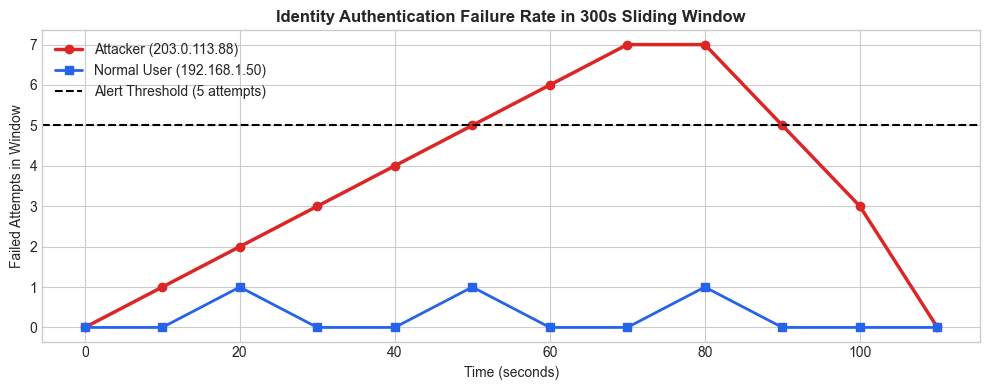

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
times = [i*10 for i in range(12)]
failures_ip1 = [0, 1, 2, 3, 4, 5, 6, 7, 7, 5, 3, 0]
failures_ip2 = [0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0]

ax.plot(times, failures_ip1, marker='o', color='#dc2626', linewidth=2.5, label='Attacker (203.0.113.88)')
ax.plot(times, failures_ip2, marker='s', color='#2563eb', linewidth=2, label='Normal User (192.168.1.50)')
ax.axhline(5, color='black', linestyle='--', linewidth=1.5, label='Alert Threshold (5 attempts)')
ax.set_title('Identity Authentication Failure Rate in 300s Sliding Window', fontsize=12, fontweight='bold')
ax.set_xlabel('Time (seconds)')
ax.set_ylabel('Failed Attempts in Window')
ax.legend()
plt.tight_layout()
plt.show()

### Step 6: Production CIEM Entitlement Audit & Summary
In production (`backend/engines/ciem_engine.py`), the identity security module:
1. Discovers unused credentials (active keys with $> 90$ days inactivity).
2. Identifies overprivileged wildcard policies (`Action: *`, `Resource: *`).
3. Emits CIEM findings with remediation guidance (auto-quarantine, credential rotation).